# Exercise 27 – Heat capacity of a three-atom cluster

**Week 5 · Molecular dynamics**

A free three-atom Lennard-Jones cluster is simulated with thermostatted MD
at a range of temperatures. From the average total energy
$\langle E\rangle(T)$ we get the heat capacity
$C = d\langle E\rangle / d(k_BT)$ by finite differences. A peak in $C$
signals a change of state – here the cluster falling apart.

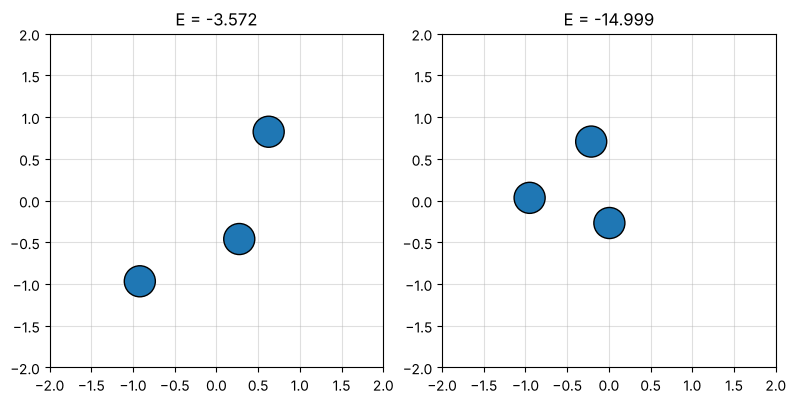

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from comphy.atoms import Cluster, LennardJones, mc_quench
from comphy.md import kinetic_energy, thermostatted_md

rng = np.random.default_rng(0)
calc = LennardJones()

cluster = Cluster(calc, rng.uniform(-1, 1, (3, 2)))
fig, axes = plt.subplots(1, 2, figsize=(8, 4))
cluster.draw(axes[0], size=500)
mc_quench(cluster, n_sweeps=2000, step=0.1, kT=0, rng=rng)
cluster.draw(axes[1], size=500)
for ax in axes:
    ax.set(xlim=(-2, 2), ylim=(-2, 2))
    ax.grid(True, alpha=0.4)
fig.tight_layout()
plt.show()

## Energy during an NVT run at $k_BT = 0.05$

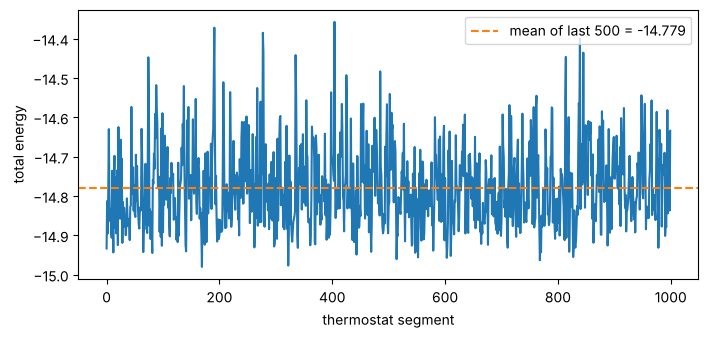

In [2]:
def total_energies(kT, n_segments=1000):
    xs, vs = thermostatted_md(cluster.positions, calc.forces, kT, n_segments=n_segments,
                              steps_per_segment=50, dt=0.01, rng=rng)
    return np.array([calc.energy(x) + kinetic_energy(v) for x, v in zip(xs, vs)])


E = total_energies(0.05)
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(E)
ax.axhline(E[-500:].mean(), color="C1", ls="--", label=f"mean of last 500 = {E[-500:].mean():.3f}")
ax.set(xlabel="thermostat segment", ylabel="total energy")
ax.legend()
plt.show()

## Mean energy and heat capacity

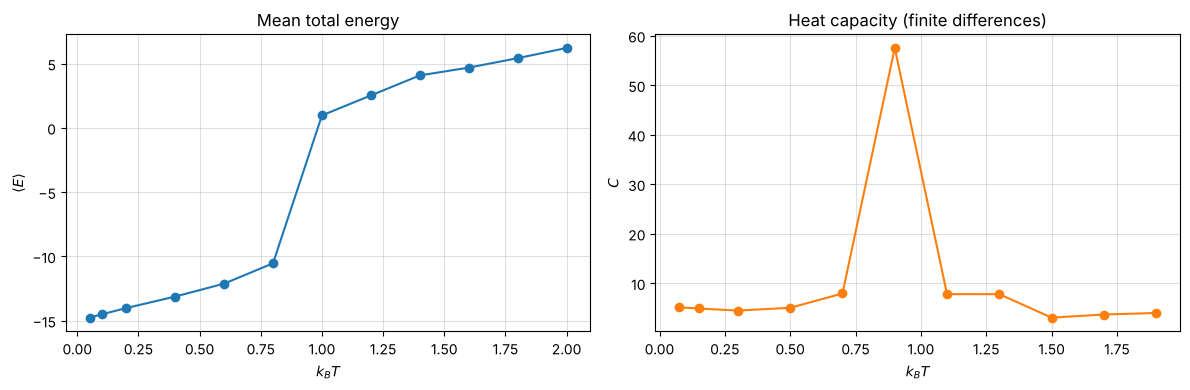

In [3]:
kTs = np.array([0.05, 0.1, 0.2, 0.4, 0.6, 0.8, 1.0, 1.2, 1.4, 1.6, 1.8, 2.0])
mean_E = np.array([total_energies(kT)[-500:].mean() for kT in kTs])
C = np.diff(mean_E) / np.diff(kTs)
kT_mid = 0.5 * (kTs[1:] + kTs[:-1])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(kTs, mean_E, "o-")
axes[0].set(xlabel="$k_BT$", ylabel=r"$\langle E\rangle$", title="Mean total energy")
axes[1].plot(kT_mid, C, "o-", color="C1")
axes[1].set(xlabel="$k_BT$", ylabel="$C$", title="Heat capacity (finite differences)")
for ax in axes:
    ax.grid(True, alpha=0.4)
fig.tight_layout()
plt.show()

At low temperature the cluster vibrates as a bound triangle and the energy
rises roughly linearly with $k_BT$. Between $k_BT = 0.8$ and $1.0$ the energy
jumps by about 12: the atoms break their bonds (the total binding energy is
$3\varepsilon = 15$) and the cluster falls apart. This shows up as a sharp
peak in the heat capacity. Above it the atoms move freely and the energy
again grows linearly. A finer temperature grid would resolve the peak better.